# Constraint Satisfaction Problem (CSP)

In today notebook we are gonna try to solve the **Graph Coloring** problem with a bunch of different techniques.\
But first, what is **graph coloring**?

## Graph Coloring

**Graph Coloring** is a classic problem in Computer Science and Optimization, categorized as a Constraint Satisfaction Problem (**CSP**). As every CSP it can be defined by a set of variables, a set of domains, a set of constraints and a goal (which is by definition finding a variable assignment that satisfies all the constraints alltogether).\
In our case:

* **Variables** ($V$): A set of vertices/nodes in a graph $G = (V, E)$.
* **Domains** ($D$): A set of available colors $C = \{c_1, c_2, \dots, c_k\}$ assigned to every node.
* **Constraints** ($C$): For every edge $(u, v) \in E$, the color assigned to $u$ must not be equal to the color assigned to $v$ ($\text{Color}(u) \neq \text{Color}(v)$).
* **Goal**: Assign a color to every node such that no two adjacent nodes share the same color, using $k$ colors.

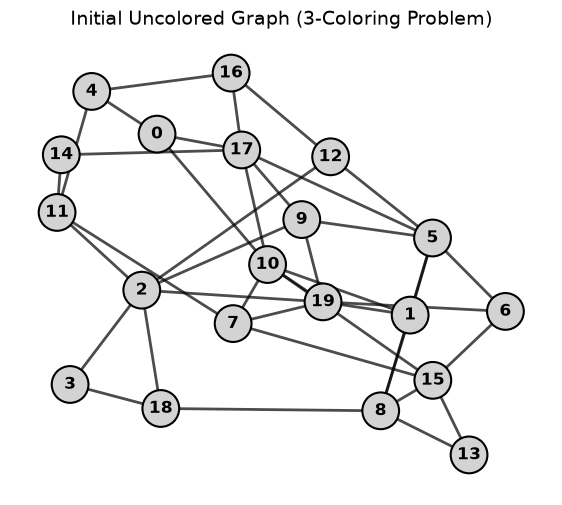

In [2]:
import networkx as nx # you will probably need to install it
import matplotlib.pyplot as plt

def draw_graph_state(G, color_map=None, title="Uncolored Graph", pos=None):
    """
    Draws the graph with given node colors.
    
    Parameters:
    - G: NetworkX graph
    - color_map: dict or list of colors corresponding to each node
    - title: title for the plot
    - pos: fixed visual layout for consistency across frames
    """
    if pos is None:
        pos = nx.spring_layout(G, seed=42) 
        
    plt.figure(figsize=(7, 6))
    
    if color_map is None:
        node_colors = ["#D3D3D3"] * len(G.nodes)
    elif isinstance(color_map, dict):
        node_colors = [color_map.get(node, "#D3D3D3") for node in G.nodes]
    else:
        node_colors = color_map
        
    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=700, edgecolors="black", linewidths=1.5)
    nx.draw_networkx_edges(G, pos, width=2, alpha=0.7)
    nx.draw_networkx_labels(G, pos, font_size=12, font_weight="bold")
    
    plt.title(title, fontsize=14)
    plt.axis("off")
    plt.show()

G = nx.fast_gnp_random_graph(n=20, p=0.2, seed=37) 
pos = nx.forceatlas2_layout(G, seed=37)

draw_graph_state(G, title="Initial Uncolored Graph (3-Coloring Problem)", pos=pos)

## Backtracing

The first thing we will like to explore is the backtracing.

Backtracking is the baseline recursive algorithm for solving CSPs. It is essentially a Depth-First Search (DFS) that exploits the structure of constraints to avoid exploring invalid paths.

How it works is pretty simple:

1. It selects an unassigned variable and tries assigning a value from its domain.
2. It checks if this assignment violates any constraints with already-assigned variables.
3. If the assignment is consistent, it recursively moves on to the next variable.
4. If a constraint is violated, or if a dead-end is reached (no colors/values left that don't violate constraints), the algorithm backtracks (undoes the last assignment) and tries a different value for that variable.

In [10]:

def backtracing(G, color_palette):
    nodes = list(G.nodes)
    history = []
    assignment = {}

    def is_valid(node, color):
        """Check if the color violates any edge constraints."""
        for neighbor in G.neighbors(node):
            if neighbor == node:
                return False
            if neighbor in assignment and assignment[neighbor] == color:
                return False
        return True

    def backtrack(node_idx):
        history.append(assignment.copy())

        # Base case: all nodes have been colored
        if node_idx == len(nodes):
            return True

        current_node = nodes[node_idx]

        for color in color_palette:
            if is_valid(current_node, color):

                # Assign color
                assignment[current_node] = color

                # Recursively color the next node
                if backtrack(node_idx + 1):
                    return True

                # Undo assignment (backtracking)
                del assignment[current_node]
                history.append(assignment.copy())

        return False

    success = backtrack(0)
    return success, assignment, history


Solution Found? True
Total steps to find the solution: 10641


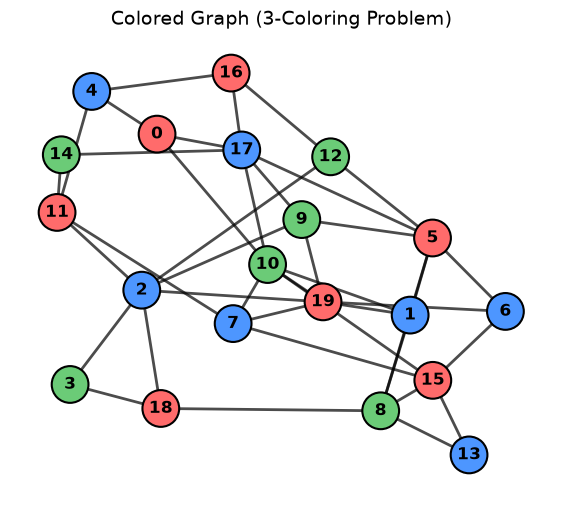

In [13]:
colors = ['#FF6B6B', '#4D96FF', '#6BCB77']

success, solution, history = backtracing(G, colors)

print(f"Solution Found? {success}")
print(f"Total steps to find the solution: {len(history)}")
draw_graph_state(G, title="Colored Graph (3-Coloring Problem)", pos=pos, color_map=solution)

## Forward Checking

We then proceed with the implementation of the forward checking.

Forward Checking is an enhancement to standard backtracking that introduces a form of look-ahead to catch failures earlier.

It works pretty much as the previous process, but:

1. Whenever a variable is assigned a value, the algorithm "looks forward" at all unassigned neighboring variables connected by a constraint.
2. It immediately removes any values from those neighbors' domains that conflict with the newly assigned value.
3. If any unassigned neighbor's domain is reduced to empty (meaning 0 legal values left), forward checking immediately recognizes that this branch will fail and triggers a backtrack without needing to descend further down the tree.

In [18]:

def forward_checking(G, color_palette):
    """
    Solves the graph coloring problem using CSP with Forward Checking.
    
    Parameters:
    - G: NetworkX graph
    - color_palette: List of available colors
    
    Returns:
    - success: Boolean indicating if a solution was found
    - final_assignment: Dict mapping nodes to colors
    - history: List of dicts recording the state at each step (for animation)
    """
    nodes = list(G.nodes)
    history = []
    
    # Initialize domains: every node starts with all colors available
    domains = {node: set(color_palette) for node in nodes}
    assignment = {}

    if any(G.has_edge(node, node) for node in nodes):
        return False, assignment, [assignment.copy()]
    
    def backtrack(node_idx):
        # Record state for visualization
        history.append(assignment.copy())
        
        # Base case: All nodes assigned
        if node_idx == len(nodes):
            return True
            
        current_node = nodes[node_idx]
        
        # Try each color currently available in the node's domain
        # Using list(domains[current_node]) to iterate over current valid options
        for color in sorted(list(domains[current_node])):
            # assign to the assignment of the current node the color that we are trying
            assignment[current_node] = color
            history.append(assignment.copy())
            
            # FORWARD CHECKING STEP
            # Remove this color from the domains of all unassigned neighbors
            failure = False
            updated_domains = {} 

            # iterate over the neighbors and remove the current color from 
            # the domain of each neighbors
            # notice: use the updated_domains structure as temporary place where 
            # to store the domain with the removel of the color
            # if an updated_domain is empty it means that failure is true
            for neighbor in G.neighbors(current_node):
                if neighbor in assignment:
                    continue

                new_domain = domains[neighbor].copy()

                if color in new_domain:
                    new_domain.remove(color)

                updated_domains[neighbor] = new_domain

                if not new_domain:
                    failure = True
                    break
                            
            if not failure:
                # if the procedure is not failed then 
                # you can go over with the next neighbor 
                # mantaining a backup domain in case the exploration 
                # arrives to a dead end
                backup_domains = {
                    neighbor: domains[neighbor].copy()
                    for neighbor in updated_domains
                }

                for neighbor, new_dom in updated_domains.items():
                    domains[neighbor] = new_dom
                    
                # Recurse to next node
                if backtrack(node_idx + 1):
                    return True 1064
                    
                # if it fails, fallback to the backup_domains
                for neighbor, old_dom in backup_domains.items():
                    domains[neighbor] = old_dom
            
            # Remove color assignment (Backtracking)
            del assignment[current_node]
            history.append(assignment.copy())
            
        return False

    success = backtrack(0) # where do we start?
    return success, assignment, history


Solution Found? True
Total steps to find the solution: 1393


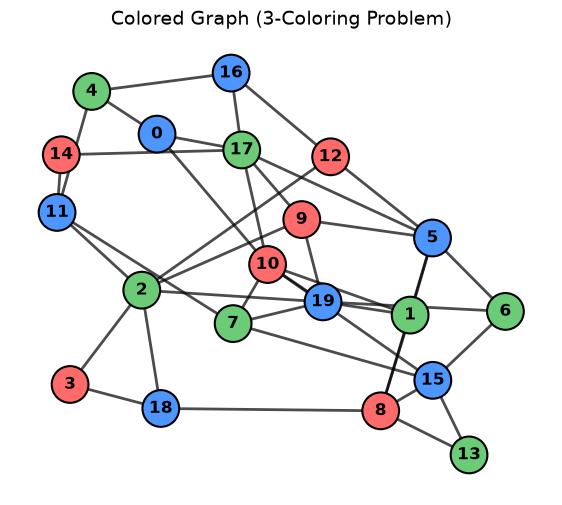

In [19]:
colors = ['#FF6B6B', '#4D96FF', '#6BCB77']

success, solution, history = forward_checking(G, colors)

print(f"Solution Found? {success}")
print(f"Total steps to find the solution: {len(history)}")
draw_graph_state(G, title="Colored Graph (3-Coloring Problem)", pos=pos, color_map=solution)

## AC-3

And we can finally proceede with the arc consistency (AC3 preciselly) implementation.

AC-3 is a powerful constraint propagation algorithm. While forward checking only updates domains after a choice is made, AC-3 is typically run before search begins (or integrated during it) to shrink domains as much as possible.

In particular, we define an "arc" as a directed constraint between two variables (e.g., Variable $X$ needs to be consistent with Variable $Y$). An arc $(X, Y)$ is arc-consistent if for every value in $X$'s domain, there is at least one valid, non-conflicting value in $Y$'s domain.

Here we define the AC-3 constraint propagation algorithm.

1. The algorithm starts with a queue containing all the arcs in the graph.
2. It pops an arc $(X, Y)$ and checks if every value in $X$'s domain has a supporting value in $Y$'s domain.
3. If a value in $X$ has no support, it is deleted from $X$'s domain.
4. If any value is deleted from $X$, all neighboring arcs pointing back to $X$ (like $(Z, X)$) are added back to the queue because their consistency might have been affected.
This repeats until the queue is empty.

Later you will use AC-3 before and within the backtracing algorithm to make the exploration tree trivial to explore.

In particular: 

1. Initialize every node with all available colors.
2. Run AC-3 to enforce arc consistency.
3. Select an unassigned node.
4. Try a color from its domain.
5. Restrict that node's domain to the chosen color.
6. Run AC-3 to propagate the consequences.
7. Recurse if consistent; otherwise restore the previous state and try another color.

Notice, in this implementation we do not use any heuristic for the queue exploration.

In [ ]:
def ac3(G, domains):
    """
    Runs the AC-3 algorithm to enforce arc consistency on the graph domains.
    Returns False if any domain becomes empty (inconsistent), True otherwise.
    """
    # Initialize queue with all directed arcs (u, v) and (v, u)
    queue = []
    for u in G.nodes():
        for v in G.neighbors(u):
            queue.append((u, v))
            
    def revise(u, v):
        # this function removes the value in the domain of u that violates the constraints wrt v
        # in that case those values are removed from the domains of u and a "True" signal
        # is returned
        # otherwise nothing change and the function return False
        revised = False
        to_remove = set()
        # For every value x in D(u), check if there is some y in D(v) where y != x
        for x in domains[u]:
            # check if x violates all in domains[v] at the same time
            ...
        if to_remove:
            domains[u] -= to_remove
        return revised
    
    while queue:
        u, v = queue.pop(0)
        if revise(u, v):
            if len(domains[u]) == 0:
                return False # Domain wiped out, problem is unsolvable with current domains
            # If domain of u changed, we must re-check all neighbors of u (except v)
            for w in G.neighbors(u):
                if w != v:
                    queue.append((w, u))
                    
    return True


def solve_graph_coloring_ac3(G, color_palette):
    """
    Solves the graph coloring problem using CSP with AC-3 (Maintaining Arc Consistency).
    
    Parameters:
    - G: NetworkX graph
    - color_palette: List of available colors
    
    Returns:
    - success: Boolean indicating if a solution was found
    - final_assignment: Dict mapping nodes to colors
    - history: List of dicts recording the state at each step (for animation)
    """
    nodes = list(G.nodes)
    history = []
    
    # Initialize domains: every node starts with all colors available
    domains = {node: set(color_palette) for node in nodes}
    assignment = {}
    
    # Initial Arc Consistency preprocessing
    if not ac3(G, domains):
        return False, {}, []

    def backtrack(node_idx):
        history.append(assignment.copy())
        
        # Base case: All nodes assigned
        if node_idx == len(nodes):
            return True
            
        current_node = nodes[node_idx]
            
        # Try each color currently available in the node's domain
        for color in sorted(list(domains[current_node])):
            # Backup current state before trying this branch
            backup_assignment = ...
            backup_domains = ...
            
            # Make assignment and restrict domain to just this color
            assignment[current_node] = ...
            domains[current_node] = ...
            history.append(assignment.copy())
            
            # Run AC-3 to propagate constraints through the network
            # And then backtrack (if the ac-3 went fine)
            ...
                    
            # Backtrack: Restore state in-place
            assignment.clear()
            assignment.update(backup_assignment)
            
            domains.clear()
            domains.update(backup_domains)

            history.append(assignment.copy())
            
        return False

    success = backtrack(...)
    return success, assignment, history

Solution Found? True
Total steps to find the solution: 55


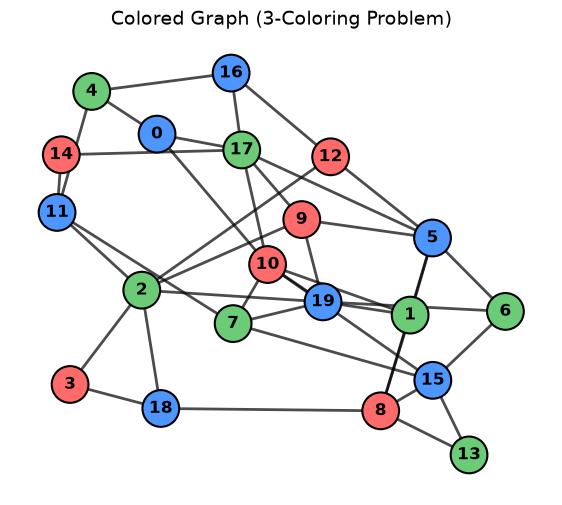

In [8]:
colors = ['#FF6B6B', '#4D96FF', '#6BCB77']

success, solution, history = solve_graph_coloring_ac3(G, colors)

print(f"Solution Found? {success}")
print(f"Total steps to find the solution: {len(history)}")
draw_graph_state(G, title="Colored Graph (3-Coloring Problem)", pos=pos, color_map=solution)

Here we add a snippet of code to visualize the assignments explored in order to find the solution.

This is not really good to understand the domains restrictions evolution.

In [11]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
import networkx as nx

def create_coloring_animation(G, history, pos=None, interval=200, filename="colormap.gif"):
    """
    Creates a matplotlib animation showing the step-by-step graph coloring history.
    
    Parameters:
    - G: NetworkX graph
    - history: List of assignment dicts generated by the solver
    - pos: Node positions for layout consistency
    - interval: Time between frames in milliseconds (lower = faster)
    
    Returns:
    - anim: FuncAnimation object renderable via HTML(anim.to_jshtml())
    """
    if pos is None:
        pos = nx.spring_layout(G, seed=42)
        
    fig, ax = plt.subplots(figsize=(7, 6))
    
    def update(frame):
        ax.clear()
        assignment = history[frame]
        
        # Build node color list based on current step's assignment
        node_colors = []
        for node in G.nodes():
            if node in assignment:
                node_colors.append(assignment[node])
            else:
                node_colors.append("#D3D3D3") # Default light gray for uncolored nodes
                
        # Draw the graph state for this frame
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors, node_size=700, edgecolors="black", linewidths=1.5)
        nx.draw_networkx_edges(G, pos, ax=ax, width=2, alpha=0.7)
        nx.draw_networkx_labels(G, pos, ax=ax, font_size=12, font_weight="bold")
        
        ax.set_title(f"Step {frame + 1} of {len(history)}", fontsize=14, fontweight="bold")
        ax.axis("off")

    # Create the animation
    anim = animation.FuncAnimation(fig, update, frames=len(history), interval=interval, repeat=True)
    
    # Close the underlying figure so it doesn't render a static duplicate plot underneath
    plt.close(fig)

    anim.save(filename, writer='pillow', fps=1)
    plt.close(fig)

    # combine this with display()
    return HTML(f'<img src="{filename}" alt="Puzzle Animation">')

In [12]:
# 1. Generate the animation object (e.g., using your AC-3 or Forward Checking history)
anim = create_coloring_animation(G, history, pos=pos, interval=150)

display(anim)